<a href="https://colab.research.google.com/github/Nihat0311/Machine-Learning/blob/main/Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from scipy.spatial.transform import Rotation
from mpl_toolkits.mplot3d import Axes3D

from sklearn.datasets import fetch_olivetti_faces


np.random.seed(7)

In [ ]:
m = 60
X = np.zeros((m,3))
np.random.seed(42)

angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5

X += 0.28 * np.random.randn(m, 3)

X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X += [0.2, 0, 0.2]

X.shape

(60, 3)

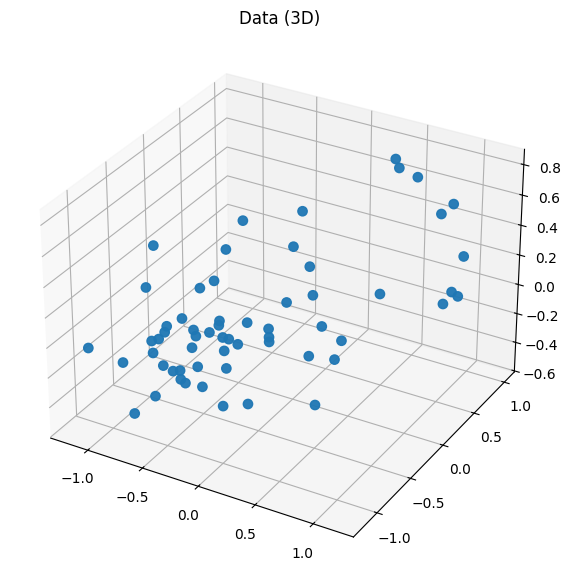

In [ ]:
fig=plt.figure(figsize=(10,7))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(X[:,0],X[:,1],X[:,2],s=45,alpha=0.95)
ax.set_title('Data (3D)')
plt.show()

In [ ]:
#ortalama
X_mean = np.mean(X, axis=0)
print(X_mean)

[-0.10328253 -0.37998889  0.08555963]


In [ ]:
X_mean.shape

(3,)

In [ ]:
X_centered=X-X_mean

In [ ]:
cov_matrix=np.cov(X_centered.T,rowvar=False)
print(cov_matrix)

[[ 0.07859119 -0.14491802 -0.04007314 ...  0.03732933  0.10481815
  -0.01907107]
 [-0.14491802  0.26722324  0.07468953 ... -0.06877384 -0.19398592
   0.03503436]
 [-0.04007314  0.07468953  0.33695227 ...  0.00459858 -0.33421166
  -0.04259284]
 ...
 [ 0.03732933 -0.06877384  0.00459858 ...  0.01949523  0.02882358
  -0.01296459]
 [ 0.10481815 -0.19398592 -0.33421166 ...  0.02882358  0.38884798
   0.02097203]
 [-0.01907107  0.03503436 -0.04259284 ... -0.01296459  0.02097203
   0.01327524]]


In [ ]:
cov_matrix=np.cov(X_centered.T,rowvar=True)
print(cov_matrix)

[[0.33894908 0.22596424 0.07588059]
 [0.22596424 0.35180308 0.08367381]
 [0.07588059 0.08367381 0.09689965]]


In [ ]:
eigen_values,elgen_vec=np.linalg.eigh(cov_matrix)
print(eigen_values)
print(elgen_vec)

[0.07111164 0.11962006 0.59692012]
[[-0.09642839 -0.72817329 -0.67857588]
 [-0.21225719  0.6811147  -0.70073508]
 [ 0.97244458  0.07646185 -0.22023881]]


In [ ]:
pca=PCA(n_components=3)
pca.fit(X_centered)

PCA(n_components=3)

In [ ]:
pca.components_ # eigen vectors

array([[ 0.67857588,  0.70073508,  0.22023881],
       [ 0.72817329, -0.6811147 , -0.07646185],
       [-0.09642839, -0.21225719,  0.97244458]])

In [ ]:
pca.explained_variance_ #eigen values

array([0.59692012, 0.11962006, 0.07111164])

In [ ]:
pca.explained_variance_ratio_

array([0.7578477 , 0.15186921, 0.09028309])

In [ ]:
pca2=PCA(n_components=2)
dim2=pca2.fit_transform(X_centered)

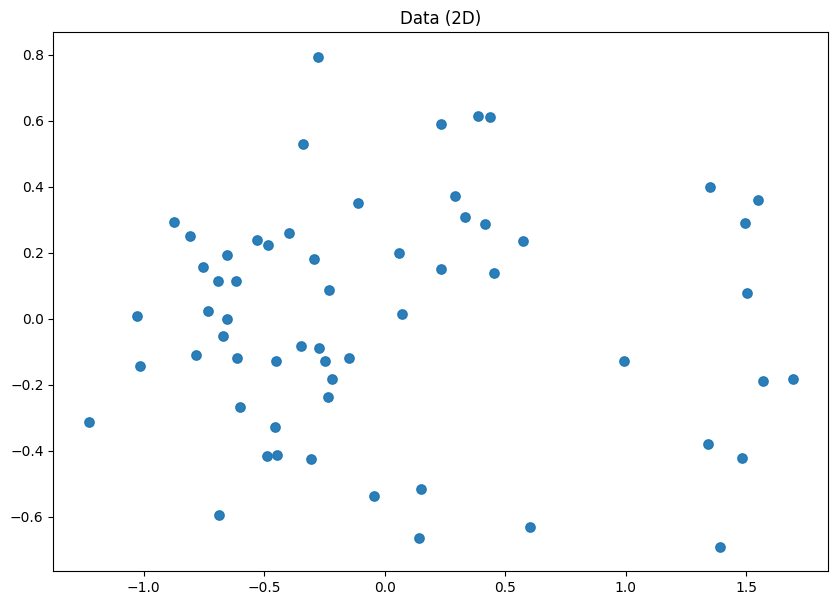

In [ ]:
plt.figure(figsize=(10,7))
plt.scatter(dim2[:,0],dim2[:,1],s=45,alpha=0.95)
plt.title('Data (2D)')
plt.show()

In [ ]:
pca1=PCA(n_components=1)
dim1=pca1.fit_transform(X_centered)

In [ ]:
x_recon=pca1.inverse_transform(dim1)
x_recon.shape

(60, 3)

In [ ]:
x_recon2=pca2.inverse_transform(dim2)
x_recon2.shape

(60, 3)

In [ ]:
mse1=np.mean((X_centered-x_recon)**2)
print(mse1)

0.06251761308873767


In [ ]:
mse2=np.mean((X_centered-x_recon2)**2)
print(mse2)

0.02330881613289282


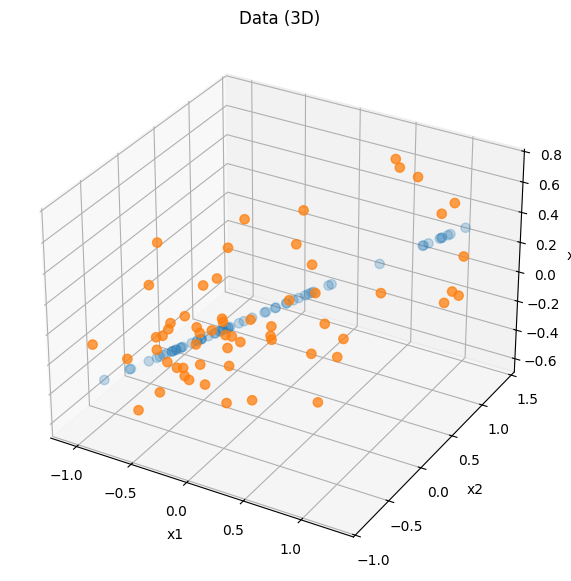

In [ ]:
fig=plt.figure(figsize=(10,7))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(x_recon[:,0],x_recon[:,1],x_recon[:,2],s=45,alpha=0.25)
ax.scatter(X_centered[:,0],X_centered[:,1],X_centered[:,2],s=45,alpha=0.75)
ax.set_title('Data (3D)')
ax.set_xlabel('x1');ax.set_ylabel('x2');ax.set_zlabel('x3')
plt.show()

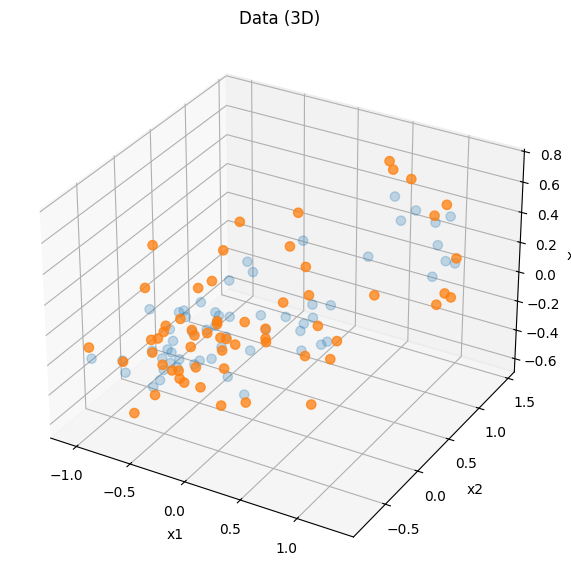

In [ ]:
fig=plt.figure(figsize=(10,7))
ax=fig.add_subplot(111,projection='3d')
ax.scatter(x_recon2[:,0],x_recon2[:,1],x_recon2[:,2],s=45,alpha=0.25)
ax.scatter(X_centered[:,0],X_centered[:,1],X_centered[:,2],s=45,alpha=0.75)
ax.set_title('Data (3D)')
ax.set_xlabel('x1');ax.set_ylabel('x2');ax.set_zlabel('x3')
plt.show()

In [ ]:
data=fetch_olivetti_faces(shuffle=True,random_state=42)
images=data.images
X=data.data


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data


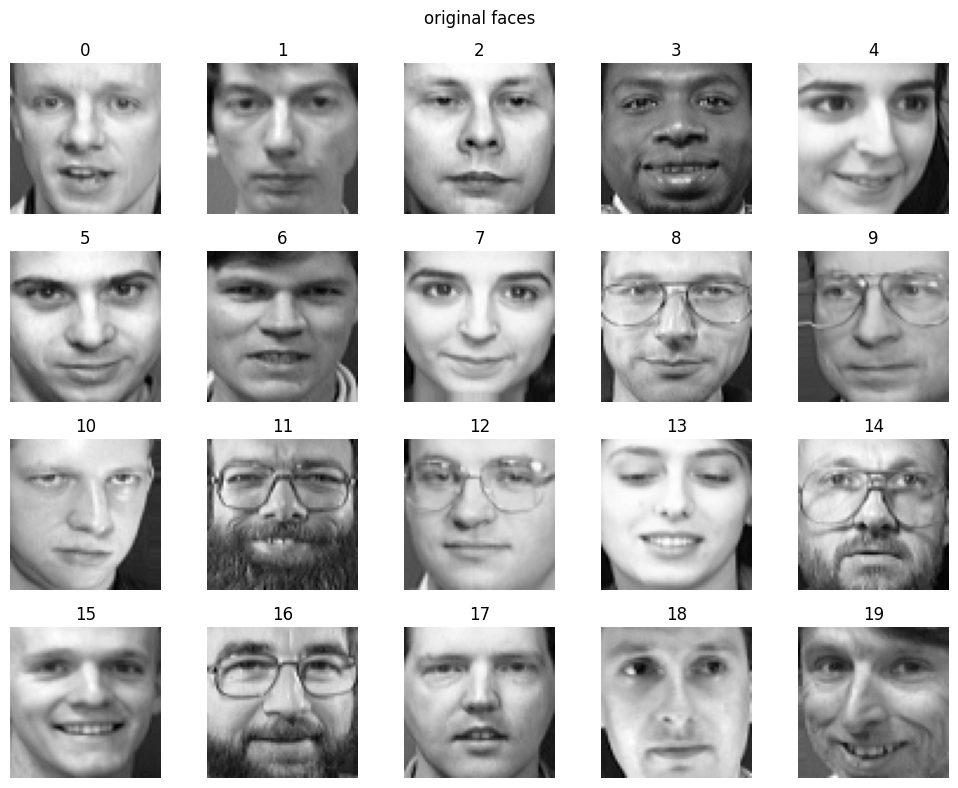

In [ ]:
plt.figure(figsize=(10,8))
for i in range(20):
  ax=plt.subplot(4,5,i+1)
  ax.imshow(images[i],cmap='gray')
  ax.set_title(f'{i}')
  ax.axis('off')
plt.suptitle('original faces')
plt.tight_layout()
plt.show()


In [ ]:
mu=X.mean(axis=0)

In [ ]:
xc=X-mu

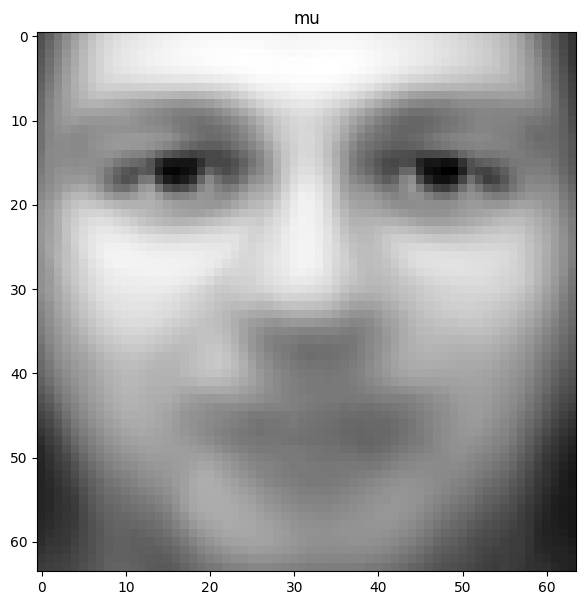

In [ ]:
plt.figure(figsize=(10,7))
plt.imshow(mu.reshape(64,64),cmap='gray')
plt.title('mu')
plt.show()

In [ ]:
pca=PCA(n_components=256,random_state=42)
pca.fit(xc)

PCA(n_components=256, random_state=42)

In [ ]:
eigen_vector=pca.components_

In [ ]:
eigen_value=pca.explained_variance_

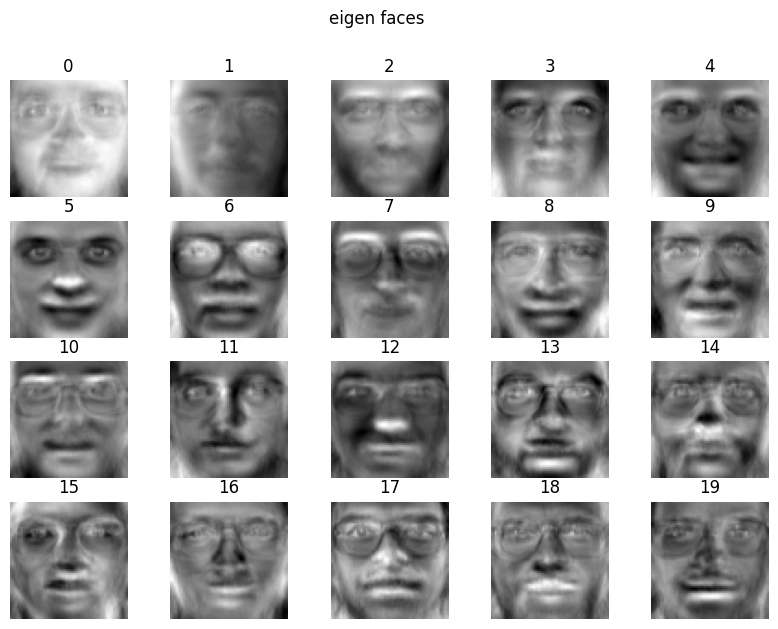

In [ ]:
plt.figure(figsize=(10,7))
for i in range(20):
  ax=plt.subplot(4,5,i+1)
  ax.imshow(eigen_vector[i].reshape(64,64),cmap='gray')
  ax.set_title(f'{i}')
  ax.axis('off')
plt.suptitle('eigen faces')
plt.show()

In [ ]:
mean_=pca.mean_

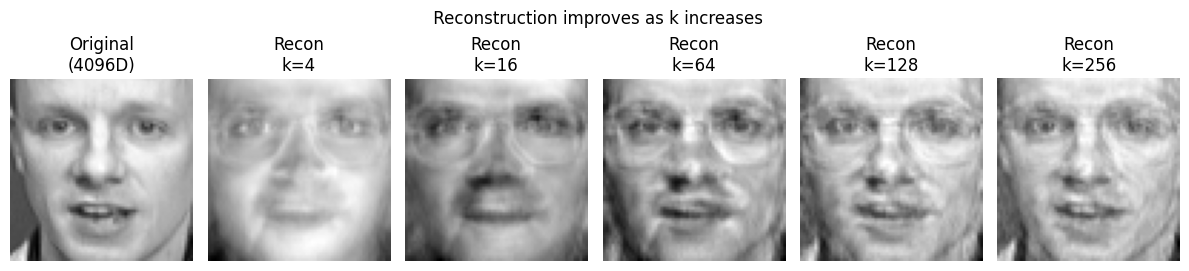

In [ ]:
idx = 0
x = X[idx:idx+1]
x_center = x - mean_

ks = [4, 16, 64, 128, 256]
recons = []

for k in ks:
    Wk = eigen_vector[:k]
    z = x_center @ Wk.T
    x_hat = z @ Wk + mean_
    recons.append(x_hat.reshape(64, 64))


plt.figure(figsize=(12, 3))
ax = plt.subplot(1, len(ks)+1, 1)
ax.imshow(x.reshape(64, 64), cmap="gray")
ax.set_title("Original\n(4096D)")
ax.axis("off")

for i, (k, img_hat) in enumerate(zip(ks, recons), start=2):
    ax = plt.subplot(1, len(ks)+1, i)
    ax.imshow(img_hat, cmap="gray")
    ax.set_title(f"Recon\nk={k}")
    ax.axis("off")

plt.suptitle(" Reconstruction improves as k increases")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import pandas as pd

In [ ]:
X, y_true = make_blobs(
    n_samples=500,
    centers=4,
    cluster_std=0.8,
    random_state=42
)

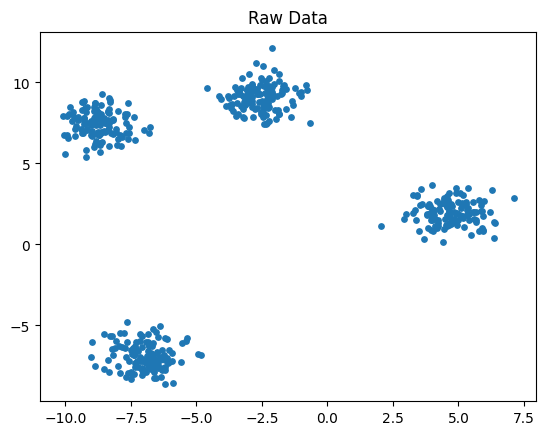

In [ ]:
plt.scatter(X[:,0],X[:,1],s=15)
plt.title("Raw Data")
plt.show()

In [ ]:
X.shape

(500, 2)

In [ ]:
np.unique(y_true)

array([0, 1, 2, 3])

In [ ]:
k=4
kmeans=KMeans(
    n_clusters=k,
    init='k-means++',
    n_init=10,
    random_state=42
)

In [ ]:
labels=kmeans.fit_predict(X)

In [ ]:
labels is kmeans.labels_

True

In [ ]:
centers=kmeans.cluster_centers_
centers

array([[ 4.70543542,  1.93371842],
       [-8.71289556,  7.42906626],
       [-6.97669736, -6.89958795],
       [-2.58361185,  9.07680526]])

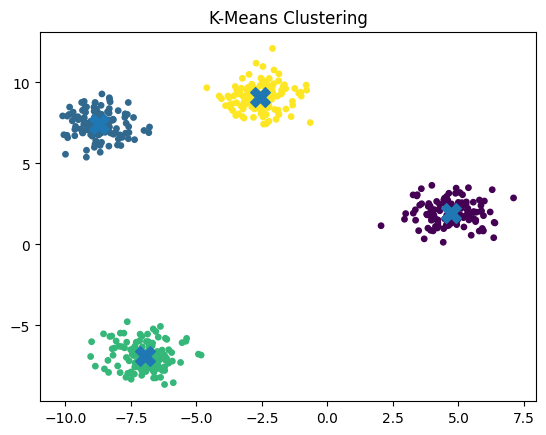

In [ ]:
plt.scatter(X[:,0],X[:,1],c=labels,s=15)
plt.scatter(centers[:,0],centers[:,1],s=200,marker='X')
plt.title("K-Means Clustering")
plt.show()

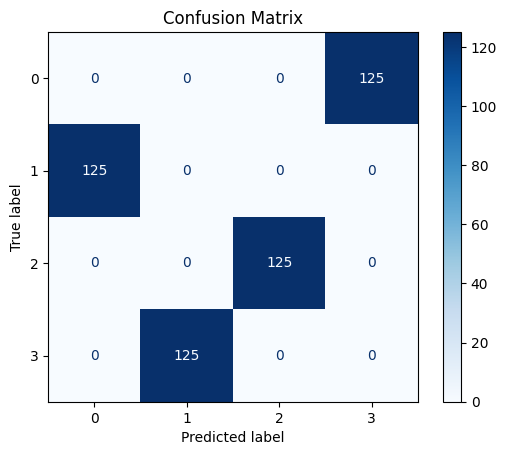

In [ ]:
cm=confusion_matrix(y_true,labels)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
kmeans.inertia_

607.2898197360992

In [ ]:
kmeans.score(X)

-607.2898197360993

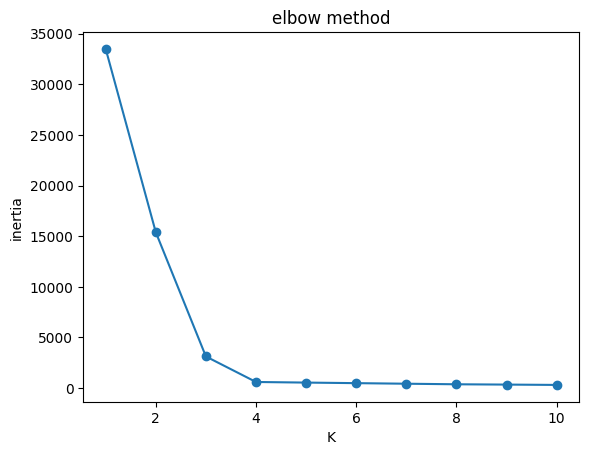

In [ ]:
inertia=[]
for i in range(1,11):
  km=KMeans(
      n_clusters=i,
      init='k-means++',
      n_init=10,
      random_state=42
  )
  km.fit(X)
  inertia.append(km.inertia_)
plt.plot(list(range(1,11)),inertia,marker='o')
plt.xlabel('K')
plt.ylabel('inertia')
plt.title('elbow method')
plt.show()

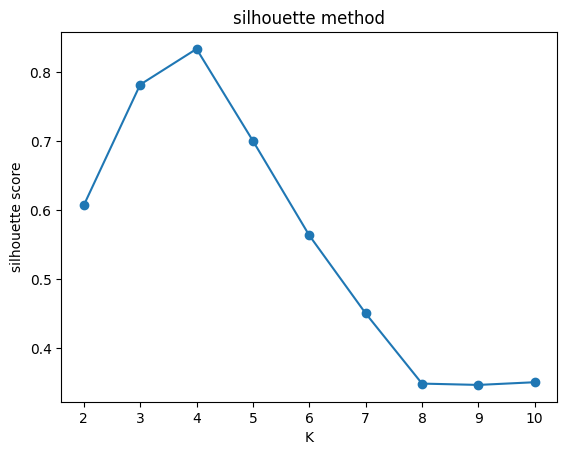

In [ ]:
sil=[]
for i in range(2,11):
  km=KMeans(
      n_clusters=i,
      init='k-means++',
      n_init=10,
      random_state=42
  )
  labels=km.fit_predict(X)
  sil.append(silhouette_score(X,labels))
plt.plot(list(range(2,11)),sil,marker='o')
plt.xlabel('K')
plt.ylabel('silhouette score')
plt.title('silhouette method')
plt.show()


In [ ]:
! curl -L -o mnist-in-csv.zip\
  https://www.kaggle.com/api/v1/datasets/download/oddrationale/mnist-in-csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 15.2M  100 15.2M    0     0  17.0M      0 --:--:-- --:--:-- --:--:--  141M


In [ ]:
!unzip /content/mnist-in-csv.zip

Archive:  /content/mnist-in-csv.zip
  inflating: mnist_test.csv          
  inflating: mnist_train.csv         


In [ ]:
df=pd.read_csv('/content/mnist_train.csv')

In [ ]:
y_true=df['label'].to_numpy()
X=df.drop(columns=['label']).to_numpy(dtype=np.float32)
X=X/255.0

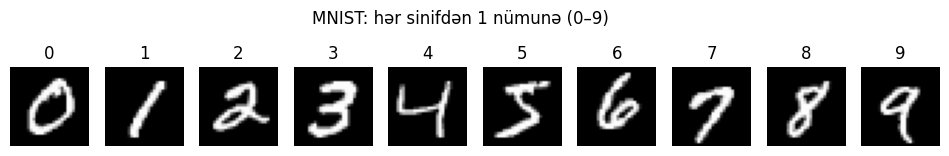

In [ ]:
sample_idx = {}
for d in range(10):
    sample_idx[d] = int(np.where(y_true == d)[0][0])

plt.figure(figsize=(12, 2))
for d in range(10):
    idx = sample_idx[d]
    img = X[idx].reshape(28, 28)

    plt.subplot(1, 10, d + 1)
    plt.imshow(img, cmap="gray")
    plt.title(str(d))
    plt.axis("off")

plt.suptitle("MNIST: hər sinifdən 1 nümunə (0–9)")
plt.show()

In [ ]:
pca=PCA(n_components=784,random_state=42)
X_pca=pca.fit_transform(X)

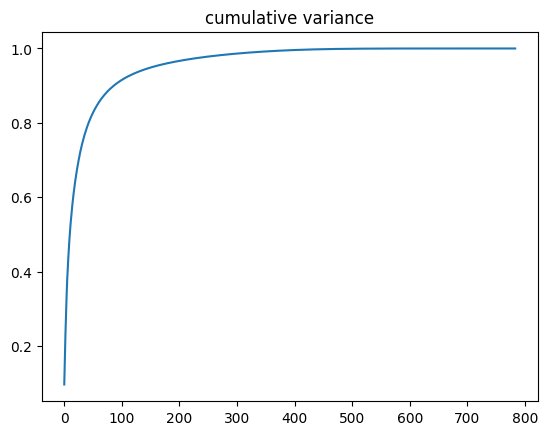

In [ ]:
cumulative_variance=np.cumsum(pca.explained_variance_ratio_)
plt.plot(cumulative_variance)
plt.title('cumulative variance')
plt.show()

In [ ]:
pca=PCA(n_components=0.95)
X_pca=pca.fit_transform(X)
print(X_pca.shape)

(60000, 154)


In [ ]:
km=KMeans(
    n_clusters=10,
    init='k-means++',
    n_init=20,
    random_state=42)
cluster_id=km.fit_predict(X_pca)

In [ ]:
cluster_to_digit={}
for i in range(10):
  mask=(cluster_id==i)
  digit=np.bincount(y_true[mask]).argmax()
  cluster_to_digit[i]=digit
cluster_to_digit

{0: np.int64(4),
 1: np.int64(1),
 2: np.int64(3),
 3: np.int64(1),
 4: np.int64(7),
 5: np.int64(8),
 6: np.int64(2),
 7: np.int64(0),
 8: np.int64(0),
 9: np.int64(6)}

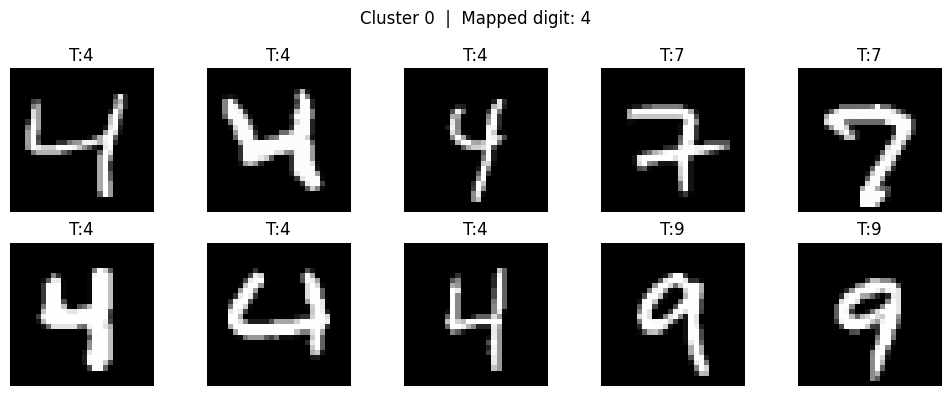

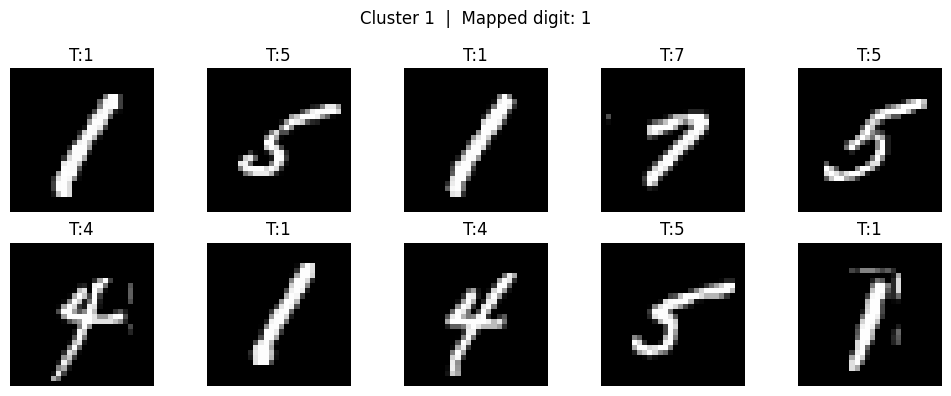

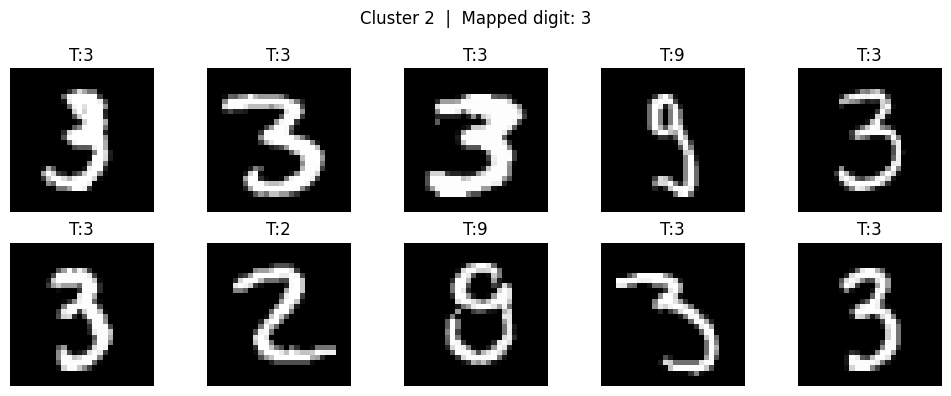

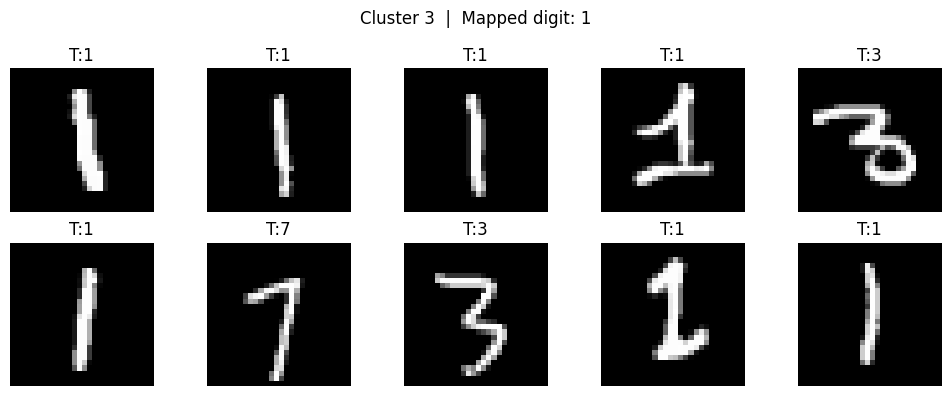

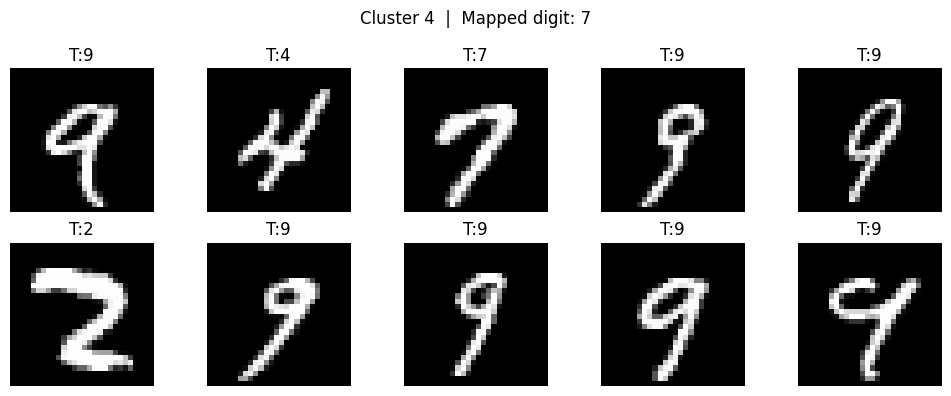

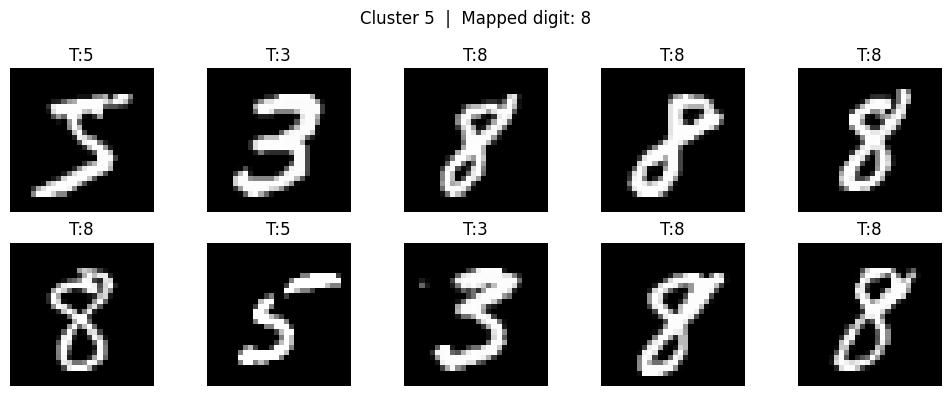

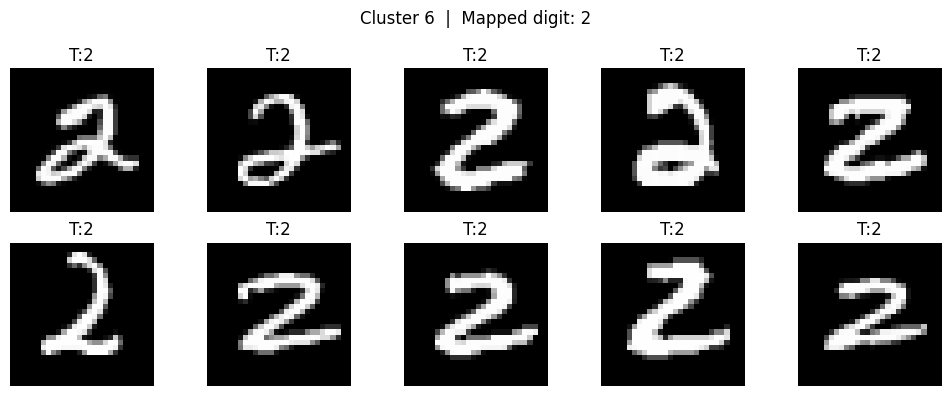

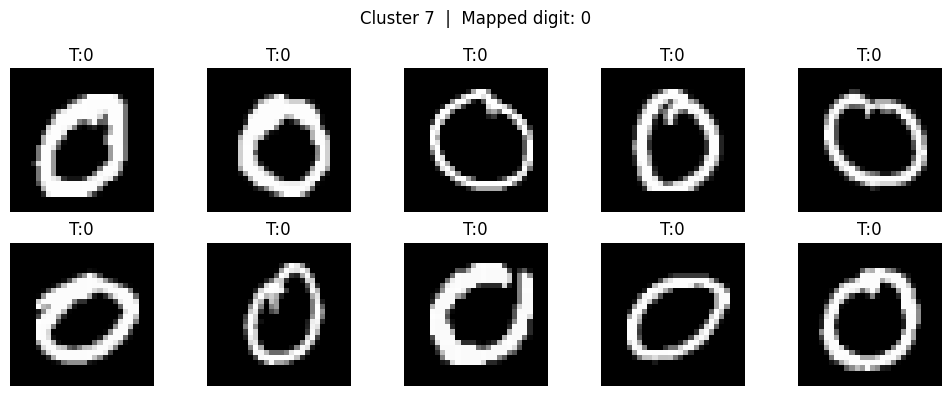

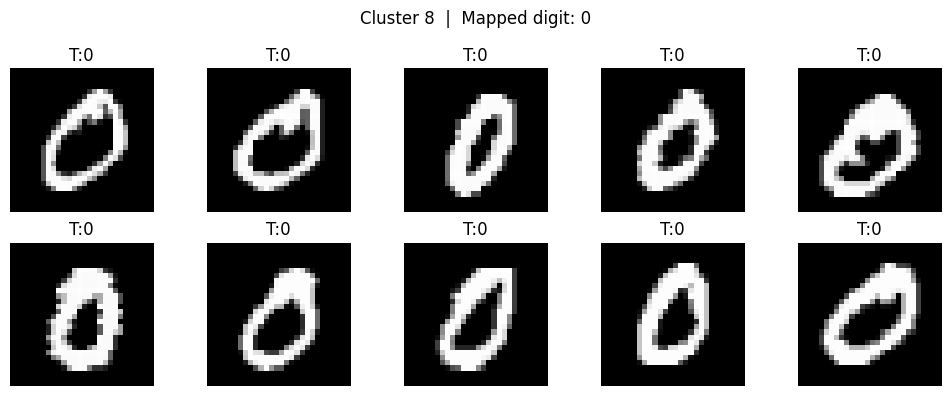

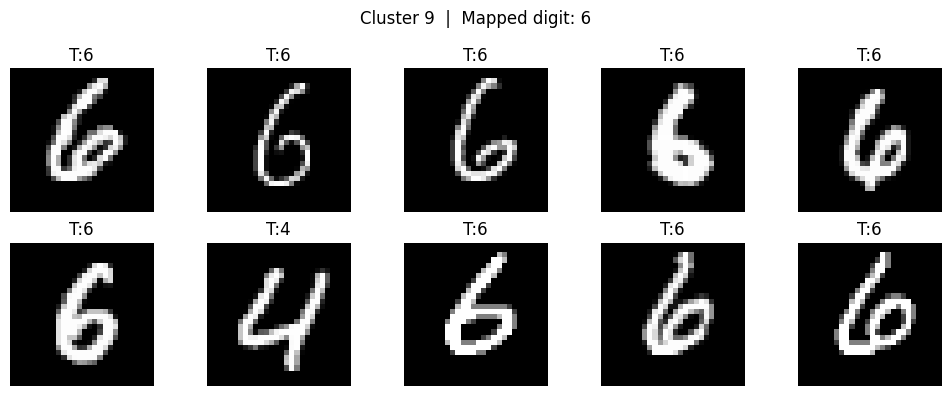

In [ ]:
def show_cluster(cluster_num, n=10):
    indices = np.where(cluster_id == cluster_num)[0][:n]

    plt.figure(figsize=(10, 4))

    for i, idx in enumerate(indices):
        img = X[idx].reshape(28, 28)
        true_label = y_true[idx]
        mapped_digit = cluster_to_digit[cluster_num]

        plt.subplot(2, 5, i+1)
        plt.imshow(img, cmap="gray")
        plt.title(f"T:{true_label}")
        plt.axis("off")

    plt.suptitle(f"Cluster {cluster_num}  |  Mapped digit: {mapped_digit}")
    plt.tight_layout()
    plt.show()
for c in range(10):
    show_cluster(c)

In [ ]:
idx=121
pred_digit=cluster_to_digit[cluster_id[idx]]
print('True digit',y_true[idx],'Pred digit',pred_digit,'Cluster',cluster_id[idx])

True digit 0 Pred digit 0 Cluster 7


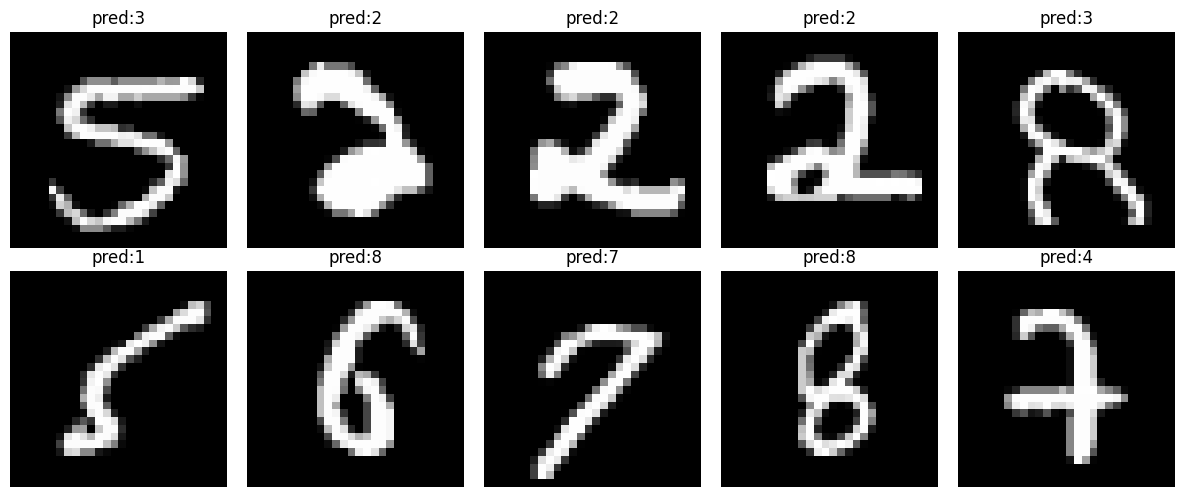

In [ ]:
indices=np.random.choice(len(X),10,replace=True)
plt.figure(figsize=(12,5))
for i,idx in enumerate(indices):
  image=X[idx].reshape(28,28)
  pred_digit=cluster_to_digit[cluster_id[idx]]
  plt.subplot(2,5,i+1)
  plt.imshow(image,cmap='gray')
  plt.title(f'pred:{pred_digit}')
  plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

In [ ]:
X, y = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=42)

dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

DBSCAN(eps=0.05)

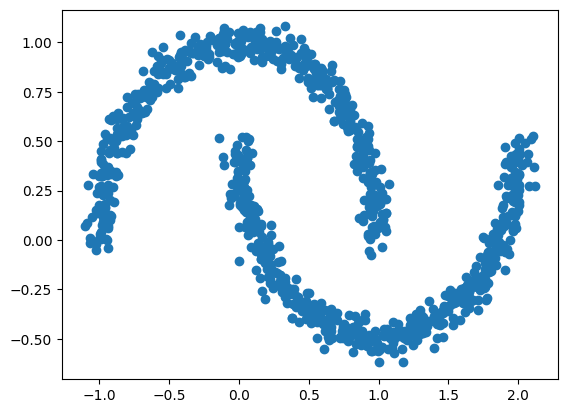

In [ ]:
plt.scatter(X[:,0],X[:,1])
plt.show()

In [ ]:
labels=dbscan.labels_
labels

array([ 0,  2, -1, -1,  1,  0,  0,  0,  2,  5,  2,  3,  0,  2,  2,  2,  4,
        2,  2,  4,  0,  5,  1,  0,  5,  5,  3,  2,  2,  2,  4,  5,  0,  6,
        1, -1,  0,  0,  2,  3, -1,  3,  4, -1,  4,  4,  2,  0,  6,  2,  0,
        2,  4,  0,  3,  3,  0,  3,  5,  2, -1,  3,  0,  5,  0,  0,  0,  2,
        3,  0,  3,  6,  0,  2,  4,  4,  0,  3,  0,  4,  0,  3, -1,  3,  4,
        0, -1,  2,  2,  4,  1,  6,  0,  5,  2,  6,  2,  3,  3, -1,  2, -1,
        2,  4,  0,  0,  0,  2,  5,  2,  0,  2, -1,  2,  3,  1,  5,  2,  0,
        4,  2,  1,  2,  4,  4,  0,  0,  6,  2,  2,  0,  2, -1,  2,  0,  3,
        3,  5, -1,  3,  3,  5,  2,  4,  2,  2,  2,  4,  2,  4,  0, -1,  2,
        1,  2,  6,  4,  2,  3,  2, -1,  2,  0,  0,  2,  0,  4,  0,  4,  4,
        1,  6,  3,  2,  6,  1,  4,  4,  2,  0,  6,  0,  1,  0,  2,  5,  1,
        1,  2,  2,  2,  2,  0,  5,  5,  1,  4,  5,  0,  3,  3,  0,  0,  0,
        2,  0,  5,  2, -1,  2,  3,  5,  2,  2,  0,  4,  0,  4,  2,  2,  4,
        2,  2,  3,  2,  3

In [ ]:
np.unique(labels)

array([-1,  0,  1,  2,  3,  4,  5,  6])

In [ ]:
for eps in [0.02,0.05,0.1,0.2]:
  db=DBSCAN(eps=eps,min_samples=5)
  labels=db.fit_predict(X)
  print(f"eps={eps},clusters={len(set(labels))-(1 if -1 in labels else 0)}")

eps=0.02,clusters=16
eps=0.05,clusters=7
eps=0.1,clusters=2
eps=0.2,clusters=2


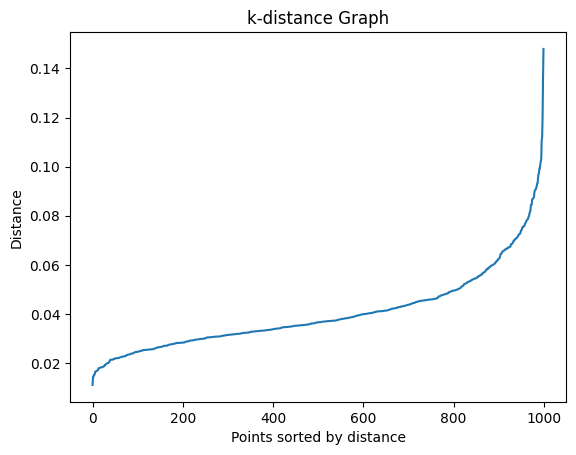

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

k = 5

neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)

k_distances = np.sort(distances[:, k-1])

plt.plot(k_distances)
plt.title("k-distance Graph")
plt.ylabel("Distance")
plt.xlabel("Points sorted by distance")
plt.show()

In [ ]:
for eps in [0.02,0.05,0.1,0.2]:
  db=DBSCAN(eps=eps,min_samples=5)
  labels=db.fit_predict(X)
  n_clusters=len(set(labels))-(1 if -1 in labels else 0)
  n_noise=list(labels).count(-1)
  print(f"eps={eps},clusters={n_clusters},noise{n_noise}")

eps=0.02,clusters=16,noise908
eps=0.05,clusters=7,noise77
eps=0.1,clusters=2,noise1
eps=0.2,clusters=2,noise0


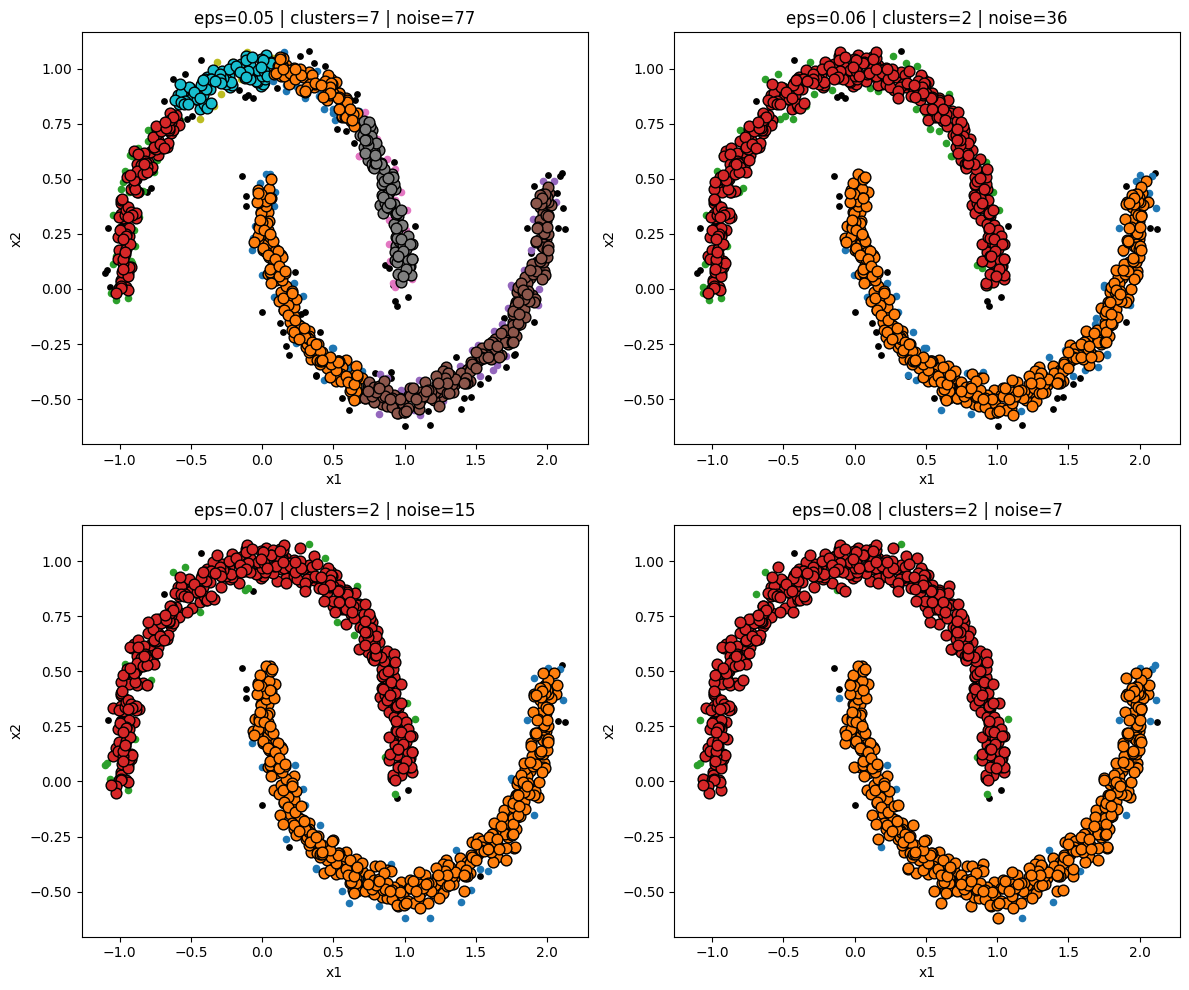

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

def plot_dbscan(ax, X, eps, min_samples=5):
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(X)
    labels = db.labels_

    core_mask = np.zeros_like(labels, dtype=bool)
    core_mask[db.core_sample_indices_] = True

    unique_labels = np.unique(labels)

    for label in unique_labels:
        mask = labels == label
        if label == -1:
            ax.scatter(X[mask, 0], X[mask, 1], c="black", s=15, label="Noise")
        else:
            border = mask & ~core_mask
            core = mask & core_mask
            ax.scatter(X[border, 0], X[border, 1], s=20)
            ax.scatter(X[core, 0], X[core, 1], s=60, edgecolors="k")

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)

    ax.set_title(f"eps={eps} | clusters={n_clusters} | noise={n_noise}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

eps_list = [0.05, 0.06, 0.07, 0.08]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, eps in zip(axes, eps_list):
    plot_dbscan(ax, X, eps, min_samples=5)

plt.tight_layout()
plt.show()

In [ ]:
! curl -L -o uber-pickups-in-new-york-city.zip\
  https://www.kaggle.com/api/v1/datasets/download/fivethirtyeight/uber-pickups-in-new-york-city

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  109M  100  109M    0     0  87.1M      0  0:00:01  0:00:01 --:--:--  127M


In [ ]:
!unzip /content/uber-pickups-in-new-york-city.zip

Archive:  /content/uber-pickups-in-new-york-city.zip
  inflating: Uber-Jan-Feb-FOIL.csv   
  inflating: other-American_B01362.csv  
  inflating: other-Carmel_B00256.csv  
  inflating: other-Dial7_B00887.csv  
  inflating: other-Diplo_B01196.csv  
  inflating: other-FHV-services_jan-aug-2015.csv  
  inflating: other-Federal_02216.csv  
  inflating: other-Firstclass_B01536.csv  
  inflating: other-Highclass_B01717.csv  
  inflating: other-Lyft_B02510.csv   
  inflating: other-Prestige_B01338.csv  
  inflating: other-Skyline_B00111.csv  
  inflating: uber-raw-data-apr14.csv  
  inflating: uber-raw-data-aug14.csv  
  inflating: uber-raw-data-janjune-15.csv  
  inflating: uber-raw-data-jul14.csv  
  inflating: uber-raw-data-jun14.csv  
  inflating: uber-raw-data-may14.csv  
  inflating: uber-raw-data-sep14.csv  


In [ ]:
import pandas as pd
df=pd.read_csv('/content/uber-raw-data-apr14.csv')

In [ ]:
df

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512
...,...,...,...,...
564511,4/30/2014 23:22:00,40.7640,-73.9744,B02764
564512,4/30/2014 23:26:00,40.7629,-73.9672,B02764
564513,4/30/2014 23:31:00,40.7443,-73.9889,B02764
564514,4/30/2014 23:32:00,40.6756,-73.9405,B02764


In [ ]:
df_small=df.sample(n=100_000,random_state=42)
print(len(df_small))

100000


In [ ]:
coords=df_small[['Lat','Lon']].dropna().to_numpy()

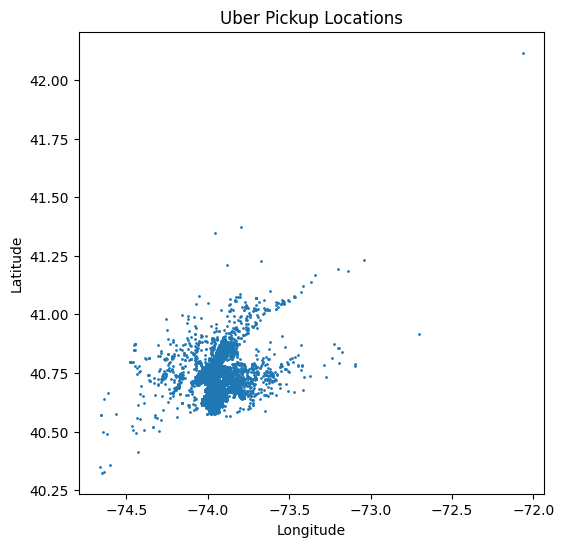

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(coords[:,1],coords[:,0],s=1)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Uber Pickup Locations')
plt.show()

In [ ]:
coords_rad=np.radians(coords)

In [ ]:
kms_per_radian=6371.0088
eps_km=0.3
eps=eps_km/kms_per_radian

db=DBSCAN(eps=eps,min_samples=30,metric='haversine')
labels=db.fit_predict(coords_rad)

In [ ]:
n_clusters=len(set(labels))-(1 if -1 in labels else 0)
n_noise=np.sum(labels==-1)
print('clusters',n_clusters,'noise',n_noise)

clusters 23 noise 4841


In [ ]:
import hdbscan
import numpy as np

clusterer=hdbscan.HDBSCAN(
    min_cluster_size=200,
    min_samples=30,
    metric='haversine'
)

labels=clusterer.fit_predict(coords_rad)

n_clusters=len(set(labels))-(1 if -1 in labels else 0)
n_noise=np.sum(labels==-1)

print('clusters',n_clusters)
print('noise',n_noise)

/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.


clusters 19
noise 5360


Hiyerarxik

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.cluster import AgglomerativeClustering

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import  BisectingKMeans

In [ ]:
X,_=make_moons(n_samples=600,noise=0.08,random_state=42)

In [ ]:
X.shape

(600, 2)

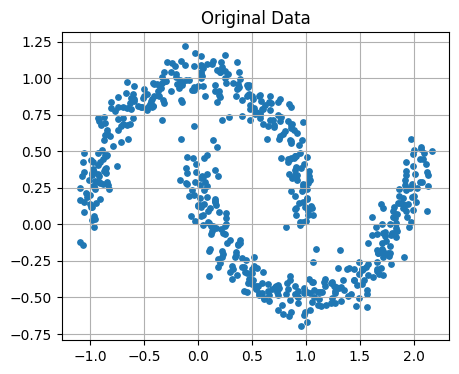

In [ ]:
plt.figure(figsize=(5,4))
plt.scatter(X[:,0],X[:,1],s=15)
plt.title("Original Data")
plt.grid(True)
plt.show()

In [ ]:
model=AgglomerativeClustering(
    n_clusters=2,
    linkage='complete'
)

labels=model.fit_predict(X)

In [ ]:
np.unique(labels)

array([0, 1])

In [ ]:
np.unique(labels,return_counts=True)

(array([0, 1]), array([369, 231]))

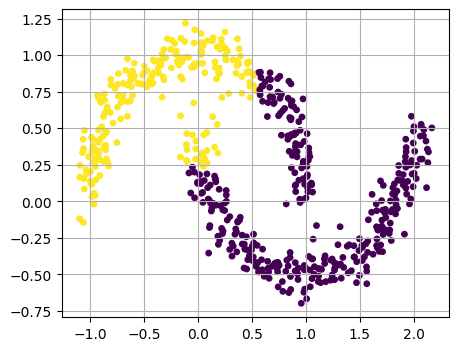

In [ ]:
plt.figure(figsize=(5,4))
plt.scatter(X[:,0],X[:,1],c=labels,s=15)
plt.grid(True)
plt.show()

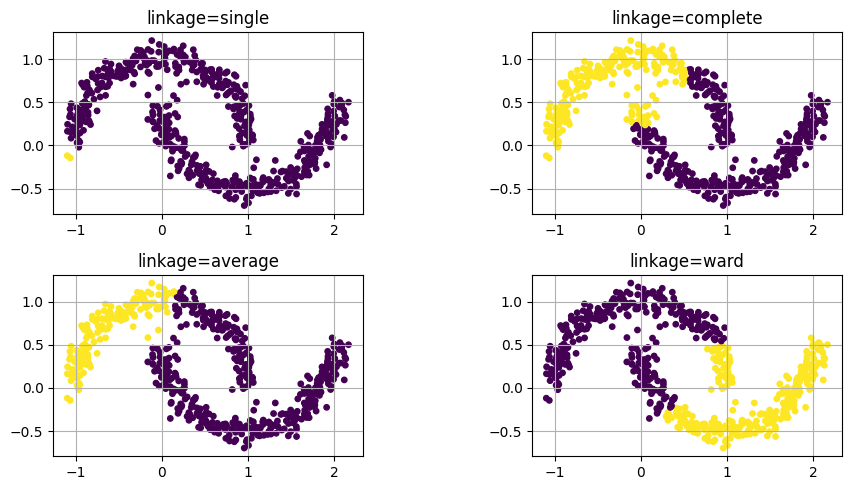

In [ ]:
ax,fig=plt.subplots(2,2,figsize=(10,5))
fig=fig.ravel()
for i,link in enumerate(['single','complete','average','ward']):
  model=AgglomerativeClustering(
      n_clusters=2,
      linkage=link
  )
  labels=model.fit_predict(X)
  fig[i].scatter(X[:,0],X[:,1],c=labels,s=15)
  fig[i].set_title(f'linkage={link}')
  fig[i].grid(True)
  fig[i].set_aspect('equal')

plt.tight_layout()
plt.show()

In [ ]:
model=AgglomerativeClustering(
    n_clusters=None,
    linkage='single',
    distance_threshold=0.15
)
labels=model.fit_predict(X)

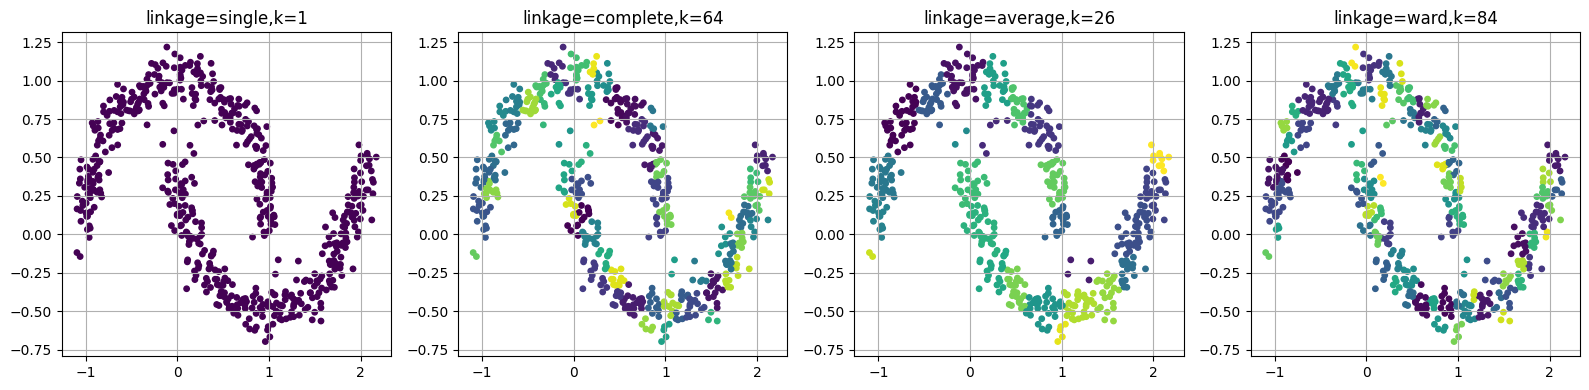

In [ ]:
linkages=['single','complete','average','ward']
t=0.25

plt.figure(figsize=(16,4))
for i,link in enumerate(linkages,1):
  model=AgglomerativeClustering(
      n_clusters=None,
      linkage=link,
      distance_threshold=t
  )
  labels=model.fit_predict(X)
  k=len(np.unique(labels))
  plt.subplot(1,4,i)
  plt.scatter(X[:,0],X[:,1],c=labels,s=15)
  plt.title(f'linkage={link},k={k}')
  plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
method='ward'
Z=linkage(X,method=method,metric='euclidean')

In [ ]:
Z

array([[5.80000000e+01, 3.20000000e+02, 1.64962320e-03, 2.00000000e+00],
       [2.74000000e+02, 4.96000000e+02, 2.78616971e-03, 2.00000000e+00],
       [2.39000000e+02, 5.36000000e+02, 3.02593697e-03, 2.00000000e+00],
       ...,
       [1.19000000e+03, 1.19400000e+03, 1.05455775e+01, 2.71000000e+02],
       [1.19300000e+03, 1.19500000e+03, 1.24560791e+01, 3.29000000e+02],
       [1.19600000e+03, 1.19700000e+03, 2.67002436e+01, 6.00000000e+02]])

In [ ]:
labels=fcluster(Z,t=0.25,criterion='distance')
np.unique(labels)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
       35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51,
       52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68,
       69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84],
      dtype=int32)

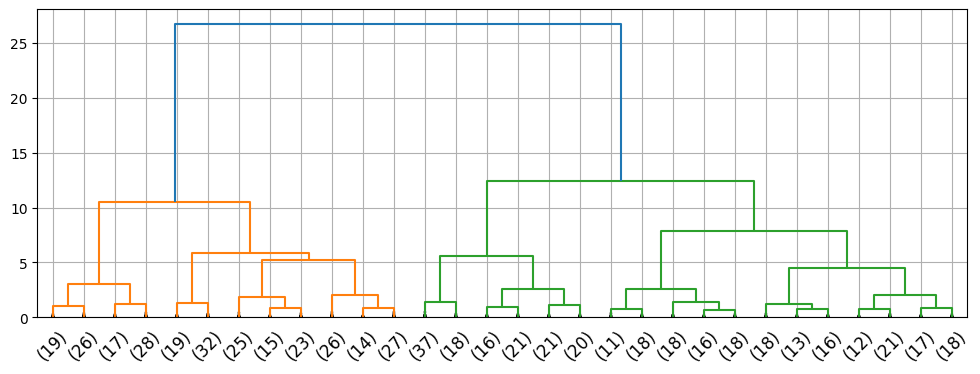

In [ ]:
plt.figure(figsize=(12,4))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    show_contracted=True,
    leaf_font_size=12
)
plt.grid(True)
plt.show()

In [ ]:
iris=load_iris()
X=iris.data
feature_names=iris.feature_names

df=pd.DataFrame(X,columns=feature_names)
print(df.shape)
df.head()

(150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [ ]:
pca=PCA(n_components=2,random_state=42)
X_pca=pca.fit_transform(X)

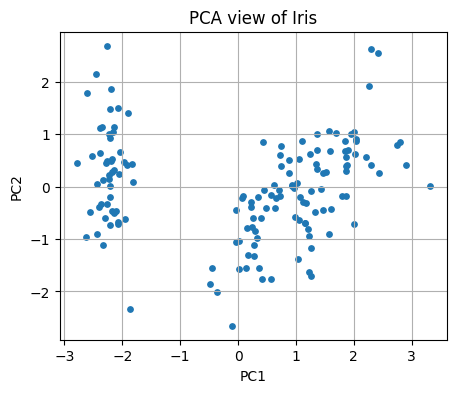

In [ ]:
plt.figure(figsize=(5,4))
plt.scatter(X_pca[:,0],X_pca[:,1],s=15)
plt.title('PCA view of Iris')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)
plt.show()

In [ ]:
method='ward'
Z=linkage(X_scaled,method=method)

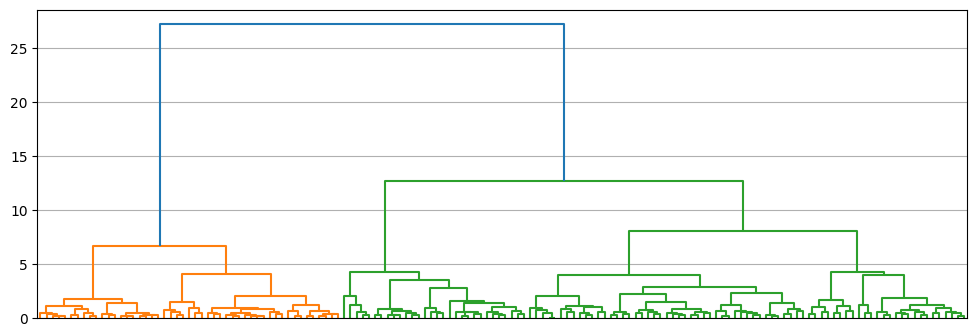

In [ ]:
plt.figure(figsize=(12,4))
dendrogram(Z,no_labels=True)
plt.grid(True)
plt.show()

In [ ]:
def clusters_from_cut(Z,t):
  labels=fcluster(Z,t=t,criterion='distance')
  k=len(np.unique(labels))
  return labels,k

In [ ]:
for t in [6,9,12,15]:
  labels,k=clusters_from_cut(Z,t)
  print(f't={t},k={k}')

t=6,k=5
t=9,k=3
t=12,k=3
t=15,k=2


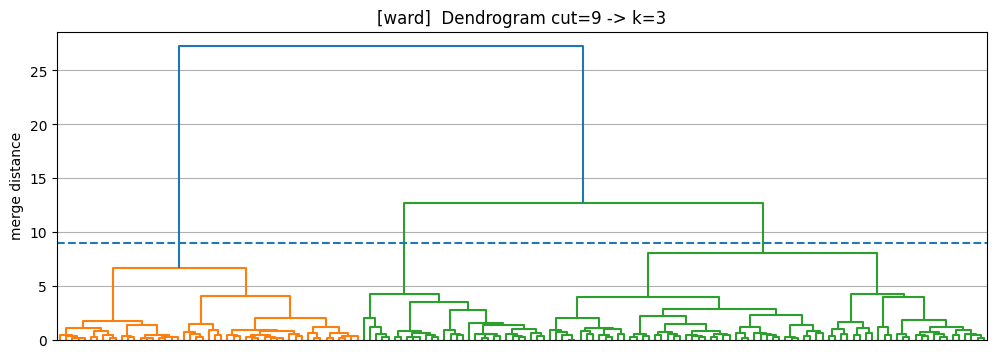

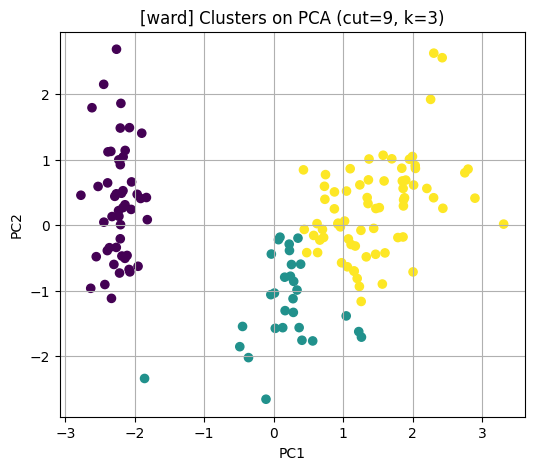

In [ ]:
def show_cut_effect(Z, X_pca, t, title_prefix=""):
    labels, k = clusters_from_cut(Z, t)

    plt.figure(figsize=(12,4))
    dendrogram(Z, no_labels=True)
    plt.axhline(y=t, linestyle="--")
    plt.title(f"{title_prefix} Dendrogram cut={t} -> k={k}")
    plt.ylabel("merge distance")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(6,5))
    plt.scatter(X_pca[:,0], X_pca[:,1], c=labels, s=35)
    plt.title(f"{title_prefix}Clusters on PCA (cut={t}, k={k})")
    plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.grid(True)
    plt.show()

    return labels


label_t9 = show_cut_effect(Z, X_pca, t=9,  title_prefix=f"[{method}] ")

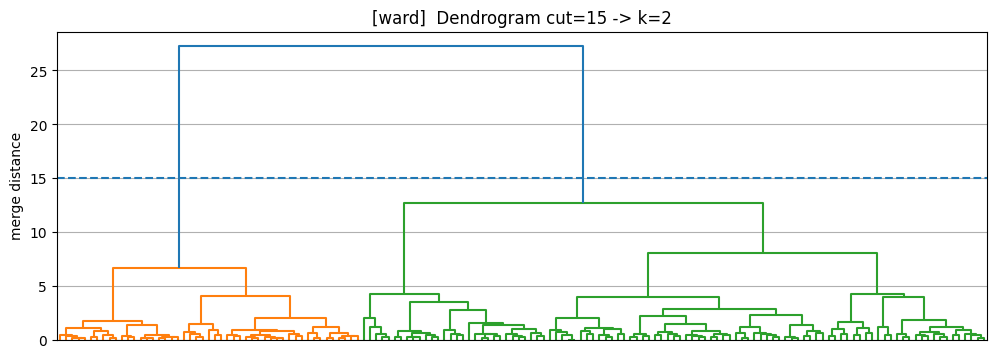

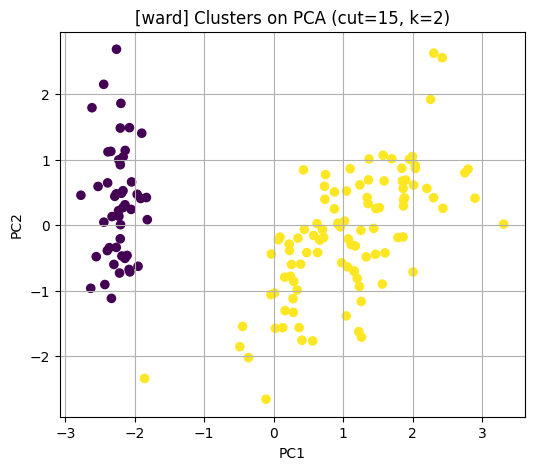

In [ ]:
label_t15 = show_cut_effect(Z, X_pca, t=15,  title_prefix=f"[{method}] ")

In [ ]:
last_10=np.sort(Z[:,2])[-10:]
print(last_10)

[ 3.44191215  3.93266869  3.95076988  4.06134011  4.22703313  4.24348495
  6.60781224  8.00474726 12.63684352 27.24991146]


In [ ]:
diffs=np.diff(last_10)
print(diffs)

[ 0.49075654  0.01810118  0.11057024  0.16569302  0.01645182  2.36432729
  1.39693502  4.63209625 14.61306794]


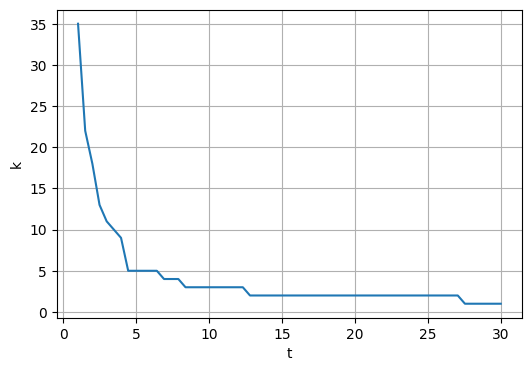

In [ ]:
ts=np.linspace(1,30,60)
ks=[]
for t in ts:
  _,k=clusters_from_cut(Z,t)
  ks.append(k)
plt.figure(figsize=(6,4))
plt.plot(ts,ks)
plt.xlabel('t')
plt.ylabel('k')
plt.grid(True)
plt.show()